In [55]:
!pip install -q streamlit openpyxl requests
print("Libraries installed successfully!")

Libraries installed successfully!


In [56]:
import io
import os
import zipfile
import requests

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
print("Downloading UCI Online Retail dataset...")
response = requests.get(url)

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall()

print("Dataset ready! Files in directory:", [f for f in os.listdir(".") if "Retail" in f or "retail" in f])

Dataset ready! Files in directory: ['Online Retail.xlsx']


In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configurations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Load Data
df = pd.read_excel("Online Retail.xlsx")
print(f"Raw shape: {df.shape}")

# 2. Flag and filter cancellations
df['IsCancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')
cancellation_rate = df['IsCancelled'].mean() * 100
print(f"Cancellation rate: {cancellation_rate:.2f}%")

# 3. Filter valid revenue records
df_clean = df[~df['IsCancelled']].dropna(subset=['CustomerID']).copy()
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 4. Correct types and extract temporal variables
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
df_clean['TotalSales'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

print(f"Cleaned shape: {df_clean.shape}")
print("Remaining null values:\n", df_clean.isnull().sum())

Raw shape: (541909, 8)
Cancellation rate: 1.71%
Cleaned shape: (397884, 13)
Remaining null values:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
IsCancelled    0
TotalSales     0
YearMonth      0
DayOfWeek      0
Hour           0
dtype: int64


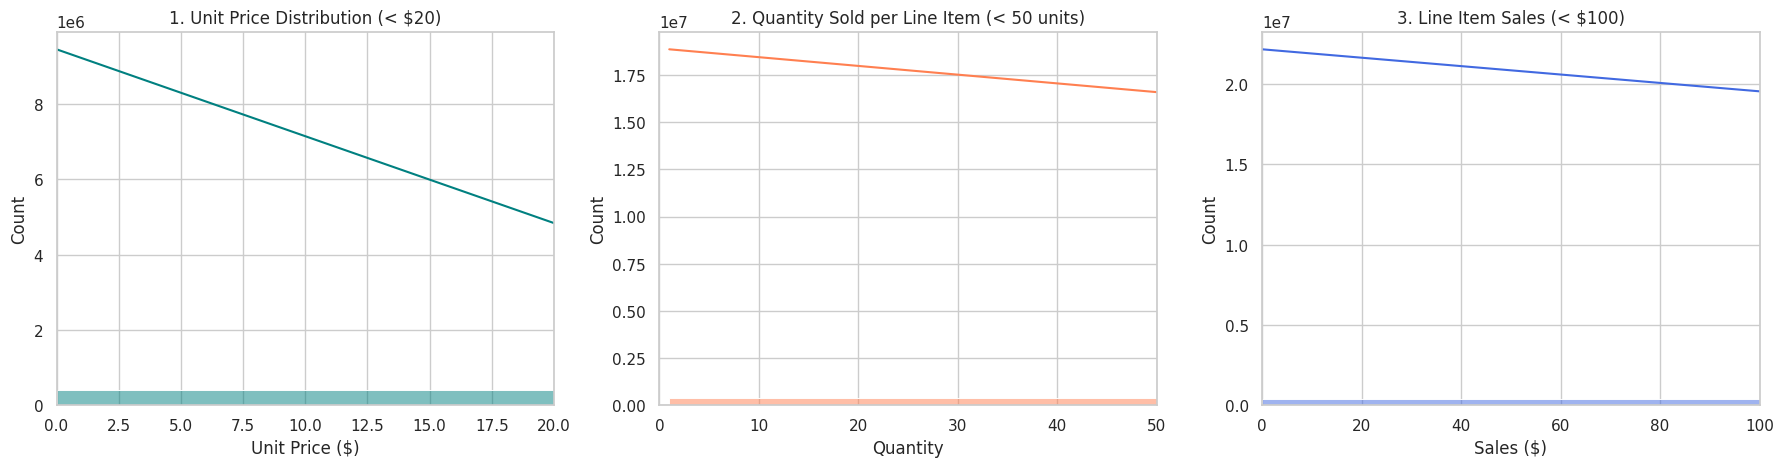

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Unit Price Distribution
sns.histplot(df_clean['UnitPrice'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_xlim(0, 20)
axes[0].set_title("1. Unit Price Distribution (< $20)")
axes[0].set_xlabel("Unit Price ($)")

# 2. Quantity Distribution
sns.histplot(df_clean['Quantity'], bins=40, kde=True, ax=axes[1], color='coral')
axes[1].set_xlim(0, 50)
axes[1].set_title("2. Quantity Sold per Line Item (< 50 units)")
axes[1].set_xlabel("Quantity")

# 3. Total Sales Distribution
sns.histplot(df_clean['TotalSales'], bins=40, kde=True, ax=axes[2], color='royalblue')
axes[2].set_xlim(0, 100)
axes[2].set_title("3. Line Item Sales (< $100)")
axes[2].set_xlabel("Sales ($)")

plt.tight_layout()
plt.show()

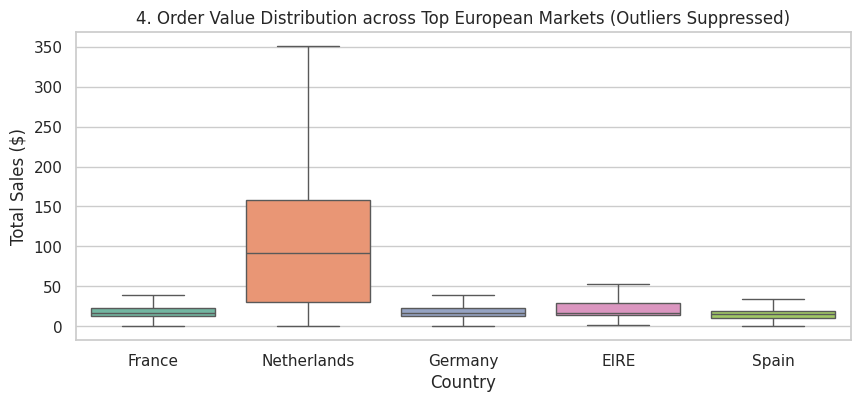

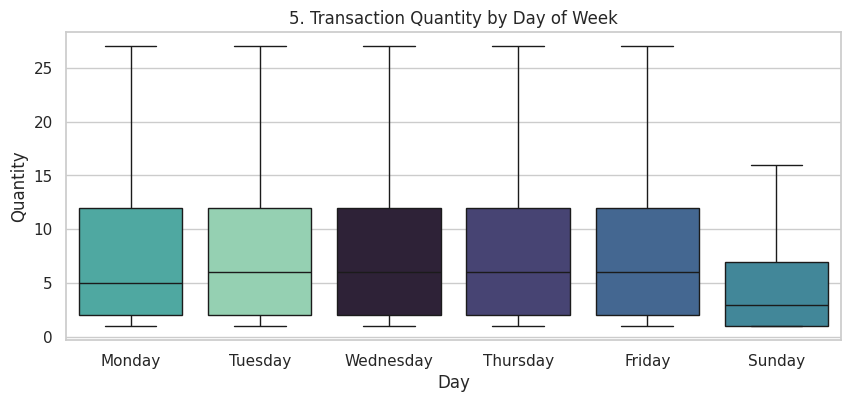

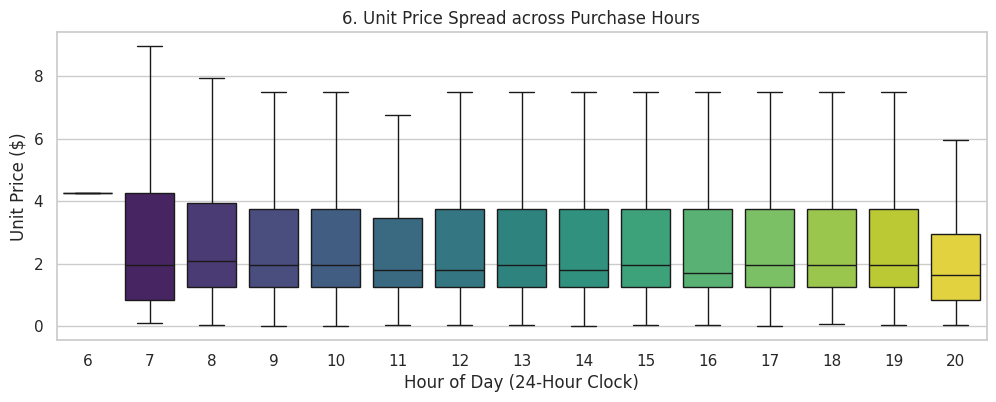

In [59]:
# 1. Sales across Top Non-UK Markets
top_non_uk = ['Germany', 'France', 'EIRE', 'Spain', 'Netherlands']
sub_df = df_clean[df_clean['Country'].isin(top_non_uk)]

plt.figure(figsize=(10, 4))
sns.boxplot(data=sub_df, x='Country', y='TotalSales', hue='Country', showfliers=False, palette='Set2', legend=False)
plt.title("4. Order Value Distribution across Top European Markets (Outliers Suppressed)")
plt.xlabel("Country")
plt.ylabel("Total Sales ($)")
plt.show()

# 2. Quantity across Days of the Week
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='DayOfWeek', y='Quantity', hue='DayOfWeek', order=days_order, showfliers=False, palette='mako', legend=False)
plt.title("5. Transaction Quantity by Day of Week")
plt.xlabel("Day")
plt.ylabel("Quantity")
plt.show()

# 3. Unit Price by Purchasing Hour
plt.figure(figsize=(12, 4))
sns.boxplot(data=df_clean, x='Hour', y='UnitPrice', hue='Hour', showfliers=False, palette='viridis', legend=False)
plt.title("6. Unit Price Spread across Purchase Hours")
plt.xlabel("Hour of Day (24-Hour Clock)")
plt.ylabel("Unit Price ($)")
plt.show()

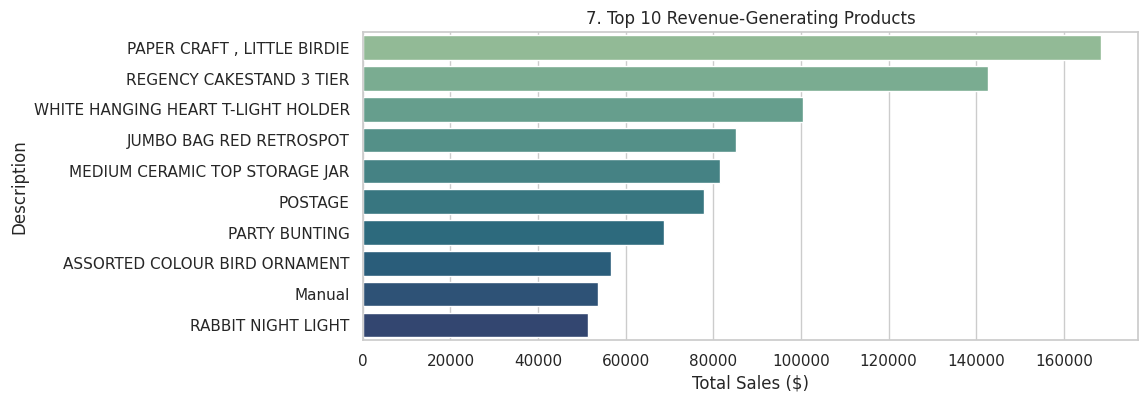

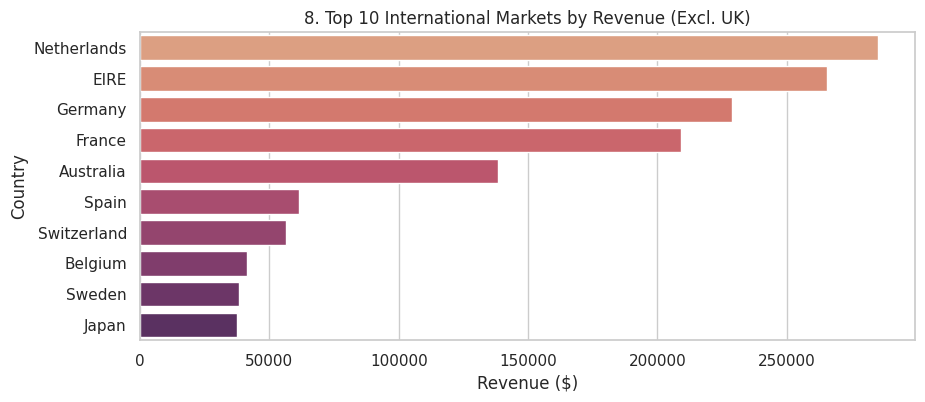

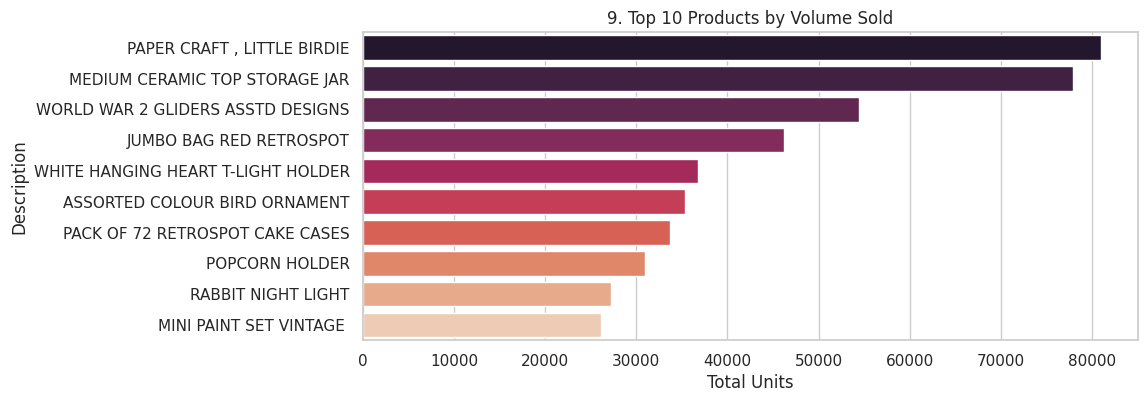

In [60]:
# 1. Top 10 Products by Revenue
top_products_rev = df_clean.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=top_products_rev.values, y=top_products_rev.index, hue=top_products_rev.index, palette='crest', legend=False)
plt.title("7. Top 10 Revenue-Generating Products")
plt.xlabel("Total Sales ($)")
plt.show()

# 2. Top 10 Non-UK Markets by Total Revenue
non_uk_rev = df_clean[df_clean['Country'] != 'United Kingdom'].groupby('Country')['TotalSales'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=non_uk_rev.values, y=non_uk_rev.index, hue=non_uk_rev.index, palette='flare', legend=False)
plt.title("8. Top 10 International Markets by Revenue (Excl. UK)")
plt.xlabel("Revenue ($)")
plt.show()

# 3. Top 10 Products by Quantity
top_products_qty = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=top_products_qty.values, y=top_products_qty.index, hue=top_products_qty.index, palette='rocket', legend=False)
plt.title("9. Top 10 Products by Volume Sold")
plt.xlabel("Total Units")
plt.show()

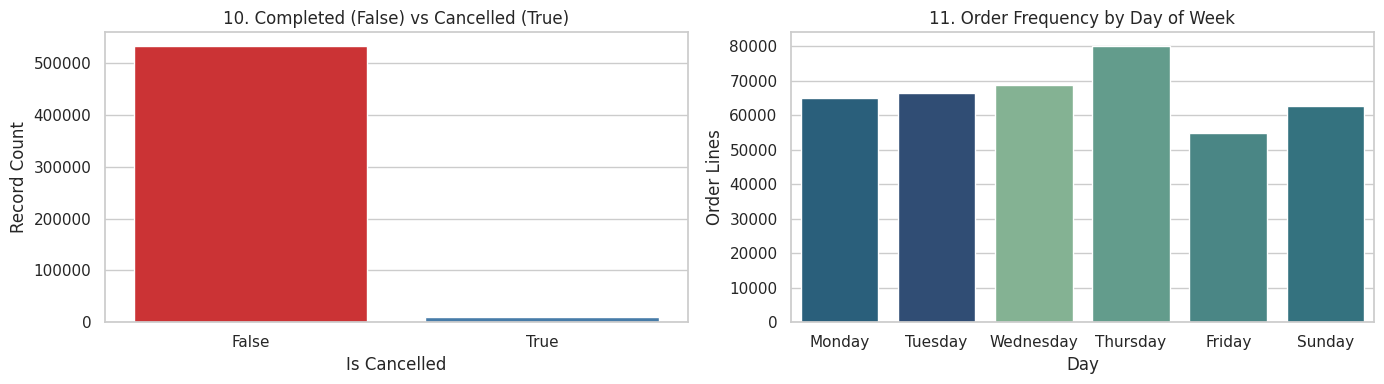

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. Completed vs Cancelled
sns.countplot(data=df, x='IsCancelled', hue='IsCancelled', ax=axes[0], palette='Set1', legend=False)
axes[0].set_title("10. Completed (False) vs Cancelled (True)")
axes[0].set_xlabel("Is Cancelled")
axes[0].set_ylabel("Record Count")

# 2. Invoices by Day of Week
sns.countplot(data=df_clean, x='DayOfWeek', hue='DayOfWeek', order=days_order, ax=axes[1], palette='crest', legend=False)
axes[1].set_title("11. Order Frequency by Day of Week")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Order Lines")

plt.tight_layout()
plt.show()

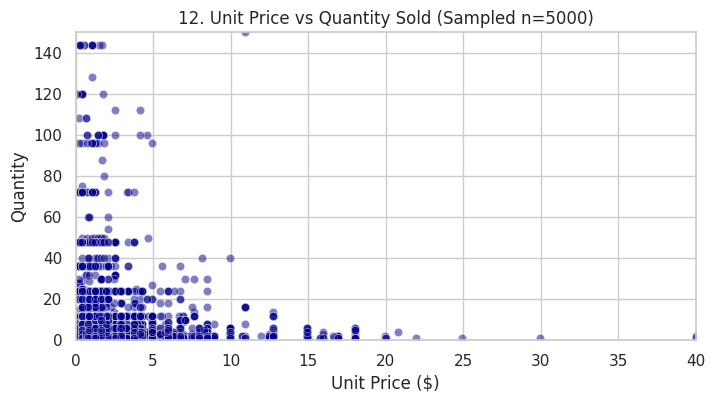

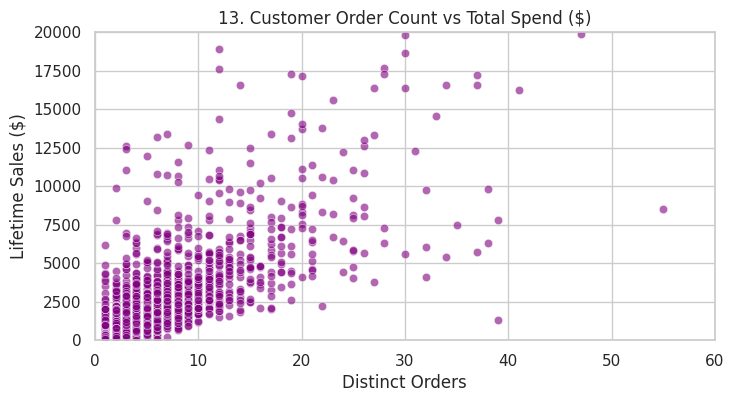

In [62]:
# 1. Unit Price vs Quantity
plt.figure(figsize=(8, 4))
sample_data = df_clean.sample(n=5000, random_state=42)
sns.scatterplot(data=sample_data, x='UnitPrice', y='Quantity', alpha=0.5, color='darkblue')
plt.xlim(0, 40)
plt.ylim(0, 150)
plt.title("12. Unit Price vs Quantity Sold (Sampled n=5000)")
plt.xlabel("Unit Price ($)")
plt.ylabel("Quantity")
plt.show()

# 2. Customer Purchase Frequency vs Total Spend
customer_summary = df_clean.groupby('CustomerID').agg({
    'InvoiceNo': 'nunique',
    'TotalSales': 'sum'
}).rename(columns={'InvoiceNo': 'OrderCount'})

plt.figure(figsize=(8, 4))
sns.scatterplot(data=customer_summary, x='OrderCount', y='TotalSales', alpha=0.6, color='purple')
plt.xlim(0, 60)
plt.ylim(0, 20000)
plt.title("13. Customer Order Count vs Total Spend ($)")
plt.xlabel("Distinct Orders")
plt.ylabel("Lifetime Sales ($)")
plt.show()

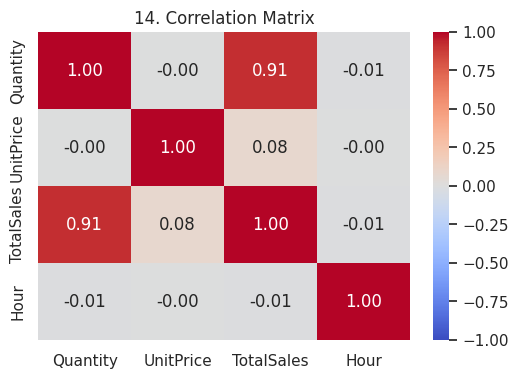

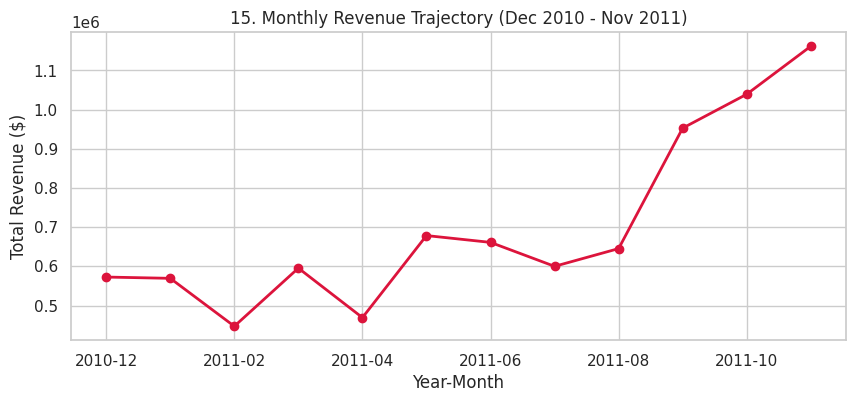

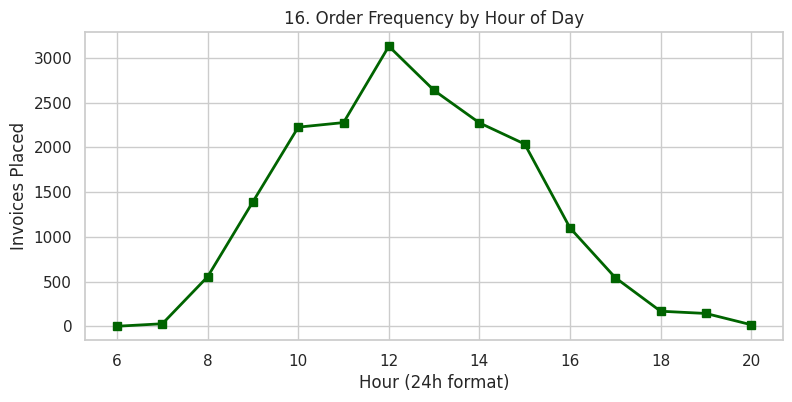

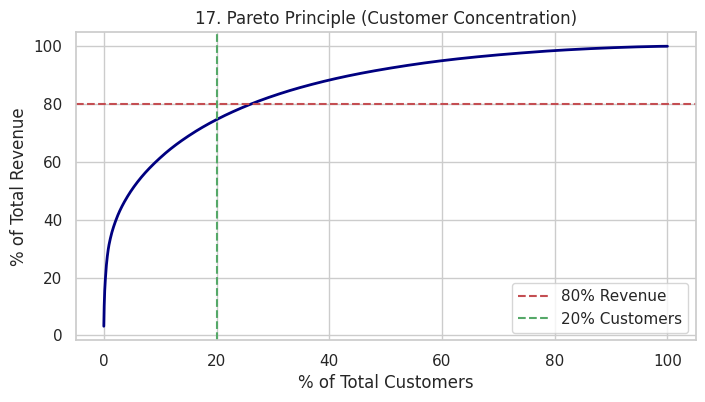

In [63]:
# 14. Correlation Heatmap
plt.figure(figsize=(6, 4))
corr = df_clean[['Quantity', 'UnitPrice', 'TotalSales', 'Hour']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("14. Correlation Matrix")
plt.show()

# 15. Time-Series: Monthly Revenue Trend
monthly_sales = df_clean.groupby('YearMonth')['TotalSales'].sum()[:-1]
plt.figure(figsize=(10, 4))
monthly_sales.plot(kind='line', marker='o', color='crimson', linewidth=2)
plt.title("15. Monthly Revenue Trajectory (Dec 2010 - Nov 2011)")
plt.ylabel("Total Revenue ($)")
plt.xlabel("Year-Month")
plt.grid(True)
plt.show()

# 16. Additional Viz 1: Peak Purchasing Hours
hourly_orders = df_clean.groupby('Hour')['InvoiceNo'].nunique()
plt.figure(figsize=(9, 4))
hourly_orders.plot(kind='line', marker='s', color='darkgreen', linewidth=2)
plt.title("16. Order Frequency by Hour of Day")
plt.xlabel("Hour (24h format)")
plt.ylabel("Invoices Placed")
plt.grid(True)
plt.show()

# 17. Additional Viz 2: Pareto Principle (80/20 Rule)
cust_pareto = customer_summary.sort_values(by='TotalSales', ascending=False)
cust_pareto['CumSales'] = cust_pareto['TotalSales'].cumsum()
cust_pareto['CumPerc'] = 100 * cust_pareto['CumSales'] / cust_pareto['TotalSales'].sum()
cust_pareto['CustPerc'] = np.linspace(0, 100, len(cust_pareto))

plt.figure(figsize=(8, 4))
plt.plot(cust_pareto['CustPerc'], cust_pareto['CumPerc'], color='navy', lw=2)
plt.axhline(80, color='r', linestyle='--', label='80% Revenue')
plt.axvline(20, color='g', linestyle='--', label='20% Customers')
plt.title("17. Pareto Principle (Customer Concentration)")
plt.xlabel("% of Total Customers")
plt.ylabel("% of Total Revenue")
plt.legend()
plt.grid(True)
plt.show()

In [64]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

st.set_page_config(
    page_title="E-Commerce EDA Portal",
    page_icon="🌿",
    layout="wide"
)

# Dark theme styling for matplotlib
sns.set_theme(style="darkgrid")
plt.rcParams['figure.facecolor'] = '#1E293B'
plt.rcParams['axes.facecolor'] = '#0F172A'
plt.rcParams['text.color'] = '#F8FAFC'
plt.rcParams['axes.labelcolor'] = '#E2E8F0'
plt.rcParams['xtick.color'] = '#CBD5E1'
plt.rcParams['ytick.color'] = '#CBD5E1'
plt.rcParams['grid.color'] = '#334155'

@st.cache_data(show_spinner=False)
def load_and_clean_data():
    if not os.path.exists("Online Retail.xlsx"):
        return None, None
    df = pd.read_excel("Online Retail.xlsx")
    df['IsCancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')
    cancellation_rate = df['IsCancelled'].mean() * 100

    df_clean = df[~df['IsCancelled']].dropna(subset=['CustomerID']).copy()
    df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
    df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)
    df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])
    df_clean['TotalSales'] = df_clean['Quantity'] * df_clean['UnitPrice']
    df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)
    df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
    df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour
    return df_clean, cancellation_rate

df_clean, cancellation_rate = load_and_clean_data()

if df_clean is None:
    st.error("Online Retail.xlsx not found.")
    st.stop()

st.sidebar.title("🎛️ Analysis Controls")
all_countries = sorted(df_clean['Country'].unique().tolist())
selected = st.sidebar.multiselect("Focus Markets:", all_countries, default=['United Kingdom', 'Germany', 'France', 'EIRE'])
filtered_df = df_clean[df_clean['Country'].isin(selected)] if selected else df_clean

st.title("🌿 E-Commerce Analytics Portal")
col1, col2, col3, col4, col5 = st.columns(5)
total_rev = filtered_df['TotalSales'].sum()
total_orders = filtered_df['InvoiceNo'].nunique()
aov = total_rev / total_orders if total_orders > 0 else 0

col1.metric("Total Revenue", f"${total_rev:,.2f}")
col2.metric("Total Orders", f"{total_orders:,}")
col3.metric("Avg Order Value", f"${aov:.2f}")
col4.metric("Active Customers", f"{filtered_df['CustomerID'].nunique():,}")
col5.metric("Cancellation Rate", f"{cancellation_rate:.2f}%")

st.markdown("---")
tab1, tab2, tab3 = st.tabs(["📈 Sales & Timing", "📦 Product Demand", "👥 Customer Cohorts"])

with tab1:
    c1, c2 = st.columns([2, 1])
    with c1:
        st.subheader("Monthly Revenue")
        m_sales = filtered_df.groupby('YearMonth')['TotalSales'].sum()
        if len(m_sales) > 1:
            m_sales = m_sales[:-1]
        fig, ax = plt.subplots(figsize=(8, 4))
        m_sales.plot(kind='line', marker='o', color='#34D399', linewidth=2.5, ax=ax)
        ax.set_ylabel("Sales ($)")
        ax.set_xlabel("Year-Month")
        st.pyplot(fig)
    with c2:
        st.subheader("Orders by Hour")
        h_orders = filtered_df.groupby('Hour')['InvoiceNo'].nunique()
        fig, ax = plt.subplots(figsize=(5, 4))
        h_orders.plot(kind='bar', color='#10B981', ax=ax)
        ax.set_xlabel("Hour of Day")
        ax.set_ylabel("Invoices Placed")
        st.pyplot(fig)

with tab2:
    top_n = st.slider("Select Top N Items:", 5, 20, 10)
    top_p = filtered_df.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(top_n)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(x=top_p.values, y=top_p.index, hue=top_p.index, palette="Greens_r", legend=False, ax=ax)
    ax.set_xlabel("Revenue ($)")
    ax.set_ylabel("Product Name")
    st.pyplot(fig)

with tab3:
    st.subheader("Customer Spend Concentration (Pareto Principle)")
    cust_summary = filtered_df.groupby('CustomerID').agg({
        'InvoiceNo': 'nunique',
        'TotalSales': 'sum'
    }).sort_values(by='TotalSales', ascending=False)
    cust_summary['CumSales'] = cust_summary['TotalSales'].cumsum()
    cust_summary['CumPerc'] = 100 * cust_summary['CumSales'] / cust_summary['TotalSales'].sum()
    cust_summary['CustPerc'] = np.linspace(0, 100, len(cust_summary))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(cust_summary['CustPerc'], cust_summary['CumPerc'], color='#34D399', lw=2.5, label='Cumulative Sales %')
    ax.axhline(80, color='#94A3B8', linestyle='--', label='80% Revenue Target')
    ax.axvline(20, color='#64748B', linestyle=':', label='20% Customer Base')
    ax.set_xlabel("% of Total Customers")
    ax.set_ylabel("% of Total Spend")
    ax.legend(frameon=True, facecolor='#1E293B', edgecolor='#334155')
    st.pyplot(fig)

Overwriting app.py


In [66]:
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb > /dev/null 2>&1
print("Cloudflared installed successfully!")

Cloudflared installed successfully!


In [67]:
import subprocess
import time
import re

# Free port 8501
!pkill -f streamlit
!pkill -f cloudflared

# Start Streamlit in the background
!nohup streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false > /dev/null 2>&1 &
time.sleep(3)

# Open the tunnel
pipe = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

# Fetch and display the link
url = None
for _ in range(30):
    line = pipe.stdout.readline()
    match = re.search(r"https://[a-zA-Z0-9\-]+\.trycloudflare\.com", line)
    if match:
        url = match.group(0)
        break
    time.sleep(0.5)

if url:
    print("\n" + "=" * 60)
    print(f"👉 CLICK TO OPEN YOUR STREAMLIT DASHBOARD:\n{url}")
    print("=" * 60 + "\n")
else:
    print("Initializing tunnel, please run this cell once more if link didn't appear.")


👉 CLICK TO OPEN YOUR STREAMLIT DASHBOARD:
https://tommy-choosing-displays-exempt.trycloudflare.com

